# Oversampling

### <i> Using SMOTE


<i> Creates synthetic samples specifically for the minority class, based on nearest neighbors. (Yes, KNN!) It's quite a useful way to synthesize data when you want to ensure the rarer combinations need representation.

In [1]:
# pip install imblearn
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# load dataset
df = pd.read_csv("../..//houses.csv")

# drop unneeded variables
df.drop(["id", "date", "lat", "long", 'zipcode'], axis=1, inplace=True)

df

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,sqft_living15,sqft_lot15
0,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,1340,5650
1,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,1690,7639
2,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,2720,8062
3,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,1360,5000
4,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,1800,7503
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21608,360000.0,3,2.50,1530,1131,3.0,0,0,3,8,1530,0,2009,0,1530,1509
21609,400000.0,4,2.50,2310,5813,2.0,0,0,3,8,2310,0,2014,0,1830,7200
21610,402101.0,2,0.75,1020,1350,2.0,0,0,3,7,1020,0,2009,0,1020,2007
21611,400000.0,3,2.50,1600,2388,2.0,0,0,3,8,1600,0,2004,0,1410,1287


In [2]:
# remove NaNs
df = df.dropna()

---

### The problem

<Axes: xlabel='waterfront', ylabel='Count'>

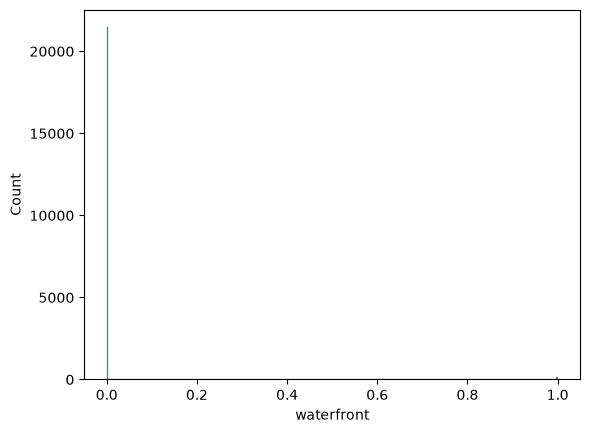

In [3]:
# Say that we're trying to make a machine learning model that
# predicts whether or not a home has a pool...

# And we look at this distribution and find that there's something very wrong.
sns.histplot(df, x="waterfront")

# The number of pools we have is massively underrepresented!
# And assume that we cannot collect any more data than this. 

# We have to create some data in order to represent the values better.

In [4]:
df['waterfront'].value_counts()

waterfront
0    21450
1      163
Name: count, dtype: int64

---

### SMOTE

In [5]:
df.shape

(21613, 16)

In [6]:
# Another x y split to prevent a data leakage
X = df.drop(columns="waterfront", axis=1)
y = df['waterfront']


<Axes: xlabel='waterfront', ylabel='Count'>

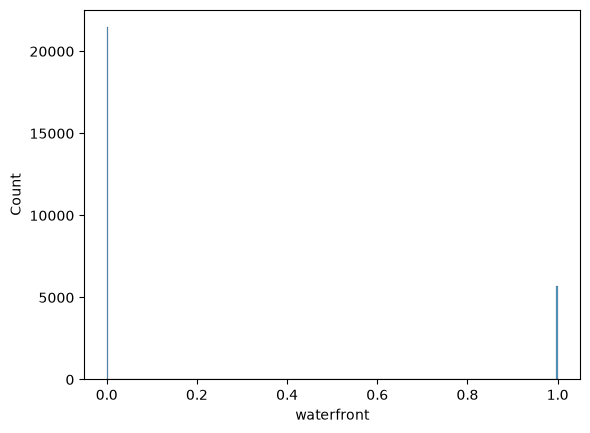

In [7]:
from imblearn.over_sampling import SMOTE

strategy = {
    0: 21450,
    1: 5713
}

smote = SMOTE(sampling_strategy=strategy)

X_resampled, y_resampled = smote.fit_resample(X, y)

# reconstruct the dataframe
df_oversampled_smote = pd.DataFrame(X_resampled)
df_oversampled_smote["waterfront"] = y_resampled

sns.histplot(df_oversampled_smote, x="waterfront")

In [8]:
df_oversampled_smote.shape

(27163, 16)

In [9]:
df_oversampled_smote['waterfront'].value_counts()

waterfront
0    21450
1     5713
Name: count, dtype: int64

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<h3>WARNING</h3>

Notice how many more rows we created here? <strong style='color:orange ; background-color:black;'> We have to be VERY careful to ensure that our data still reflects reality. </strong>

In this case, we added WAY too many rows. Not everyone has a pool! And what's worse, synthetic data is really volatile. 

</div>

In [10]:
# switching to decimal notation for the variance checks
pd.set_option('display.float_format', lambda x: "%.2f" % x)

In [11]:
df.describe()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,sqft_living15,sqft_lot15
count,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00,21613.00
mean,540088.14,3.37,2.11,2079.90,15106.97,1.49,0.01,0.23,3.41,7.66,1788.39,291.51,1971.01,84.40,1986.55,12768.46
std,367127.20,0.93,0.77,918.44,41420.51,0.54,0.09,0.77,0.65,1.18,828.09,442.58,29.37,401.68,685.39,27304.18
min,75000.00,0.00,0.00,290.00,520.00,1.00,0.00,0.00,1.00,1.00,290.00,0.00,1900.00,0.00,399.00,651.00
25%,321950.00,3.00,1.75,1427.00,5040.00,1.00,0.00,0.00,3.00,7.00,1190.00,0.00,1951.00,0.00,1490.00,5100.00
50%,450000.00,3.00,2.25,1910.00,7618.00,1.50,0.00,0.00,3.00,7.00,1560.00,0.00,1975.00,0.00,1840.00,7620.00
75%,645000.00,4.00,2.50,2550.00,10688.00,2.00,0.00,0.00,4.00,8.00,2210.00,560.00,1997.00,0.00,2360.00,10083.00
max,7700000.00,33.00,8.00,13540.00,1651359.00,3.50,1.00,4.00,5.00,13.00,9410.00,4820.00,2015.00,2015.00,6210.00,871200.00


In [12]:
df_oversampled_smote.describe()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,sqft_living15,sqft_lot15,waterfront
count,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00,27163.00
mean,766971.19,3.28,2.23,2299.10,16617.50,1.52,0.93,3.38,7.81,1919.71,379.31,1969.00,169.77,2127.81,14328.44,0.21
std,739261.29,0.94,0.86,1146.55,38831.16,0.53,1.56,0.63,1.32,930.75,528.85,28.60,511.12,752.71,25517.60,0.41
min,75000.00,0.00,0.00,290.00,520.00,1.00,0.00,1.00,1.00,290.00,0.00,1900.00,0.00,399.00,651.00,0.00
25%,350000.00,3.00,1.75,1500.00,5720.00,1.00,0.00,3.00,7.00,1240.00,0.00,1949.00,0.00,1546.00,5728.50,0.00
50%,520000.00,3.00,2.25,2060.00,8545.00,1.50,0.00,3.00,8.00,1670.00,0.00,1969.00,0.00,1979.00,8410.00,0.00
75%,819926.01,4.00,2.50,2810.00,14702.00,2.00,2.00,4.00,8.00,2400.00,700.00,1993.00,0.00,2600.50,13327.50,0.00
max,7700000.00,33.00,8.00,13540.00,1651359.00,3.50,4.00,5.00,13.00,9410.00,4820.00,2015.00,2015.00,6210.00,871200.00,1.00


In [13]:
df.var(numeric_only=True)

price           134782378397.25
bedrooms                   0.87
bathrooms                  0.59
sqft_living           843533.68
sqft_lot          1715658774.18
floors                     0.29
waterfront                 0.01
view                       0.59
condition                  0.42
grade                      1.38
sqft_above            685734.67
sqft_basement         195872.67
yr_built                 862.80
yr_renovated          161346.21
sqft_living15         469761.24
sqft_lot15         745518225.34
dtype: float64

In [14]:
df_oversampled_smote.var(numeric_only=True)

price           546507261232.80
bedrooms                   0.89
bathrooms                  0.73
sqft_living          1314577.75
sqft_lot          1507859241.51
floors                     0.28
view                       2.44
condition                  0.40
grade                      1.73
sqft_above            866296.03
sqft_basement         279685.09
yr_built                 818.11
yr_renovated          261246.49
sqft_living15         566568.40
sqft_lot15         651147876.13
waterfront                 0.17
dtype: float64

<Axes: >

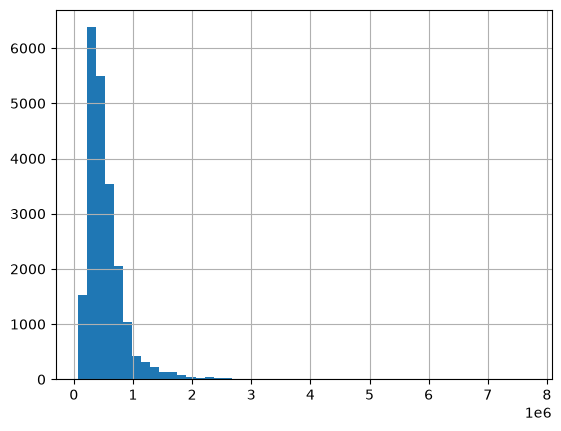

In [15]:
df['price'].hist(bins=50)

<Axes: >

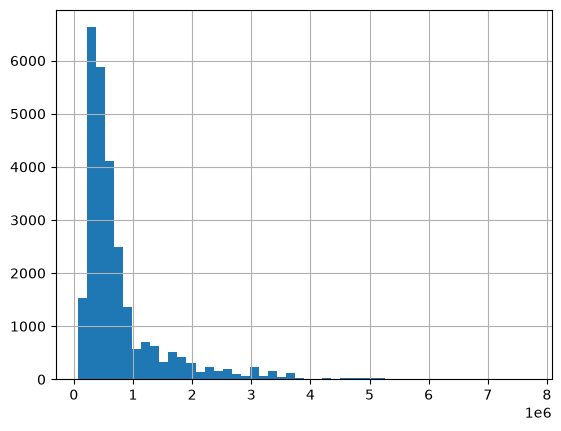

In [16]:
df_oversampled_smote['price'].hist(bins=50)

In [ ]:
# to be added later => extract only the synthetic ones from the oversampled df
# so we can actually study the synthesized houses here

# got this from AI / ChatGPT
diff = (
    df_oversampled_smote.merge(df.drop_duplicates(), how="left", indicator=True)
       .query('_merge == "left_only"')
       .drop(columns="_merge")
)

# these are the synthetic ones only
# SMOTE also falls for the trap => renovations in the past, built the house in future
diff

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,sqft_living15,sqft_lot15,waterfront
21613,2538317.47,3,3.47,5035,41368,2.00,4,3,11,4231,803,1994,0,3314,15120,1
21614,750000.00,3,1.92,2620,32656,1.23,3,3,8,1770,849,1966,0,1848,15692,1
21615,1651128.54,3,2.75,2768,9859,1.91,4,4,9,2620,147,1972,1803,2893,8712,1
21616,854624.76,2,1.85,1864,16948,1.21,3,3,7,1231,633,1952,414,1597,13003,1
21617,1893047.30,5,3.58,3092,17651,2.00,3,3,8,2962,129,1937,1431,3638,14971,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27158,1370721.27,3,3.36,3414,37286,1.11,4,3,9,1977,1436,1972,1555,2890,32292,1
27159,3661589.18,4,3.35,4923,22162,2.00,4,4,11,4923,0,1989,0,3899,25301,1
27160,1664657.54,3,2.40,3183,7457,1.59,4,4,8,1930,1253,1947,1167,2816,10582,1
27161,323425.19,3,0.92,948,10666,1.00,3,3,5,948,0,1962,0,1408,40443,1
